# **Biomarker comparison**

This notebook compares the SV biomarkers selected by the three models evaluated with nested cross-validation (XGBoost, Logistic Regression, KNN). Each biomarker file contains the SVs of the top clusters of one model, with the model's score for that cluster.

Unlike for the CNVs, all three models use the same clusters (from notebook 3), so clusters can be compared directly between models.

#### **Contents**
1. How many biomarkers are shared? (Venn diagrams)
2. Which SVs are shared?
3. What kind of SVs does each model pick?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib_venn import venn3

sns.set_style('whitegrid')

In [2]:
knn = pd.read_csv("Results/biomarkers_knn.csv")
logreg = pd.read_csv("Results/biomarkers_logreg.csv")
xgb = pd.read_csv("Results/biomarkers_xgb.csv")

# All selected SVs (background for the comparisons)
all_selected = pd.read_csv("Data/clusters.csv")

biomarkers = {'KNN': knn, 'LogReg': logreg, 'XGBoost': xgb}
sets_features = {name: set(df.feature) for name, df in biomarkers.items()}
sets_cluster = {name: set(df.cluster) for name, df in biomarkers.items()}

for name, df in biomarkers.items():
    print(f"{name}: {df.cluster.nunique()} clusters, {df.feature.nunique()} SVs")

KNN: 100 clusters, 100 SVs
LogReg: 100 clusters, 100 SVs
XGBoost: 100 clusters, 100 SVs


## **1. How many biomarkers are shared? (Venn diagrams)**

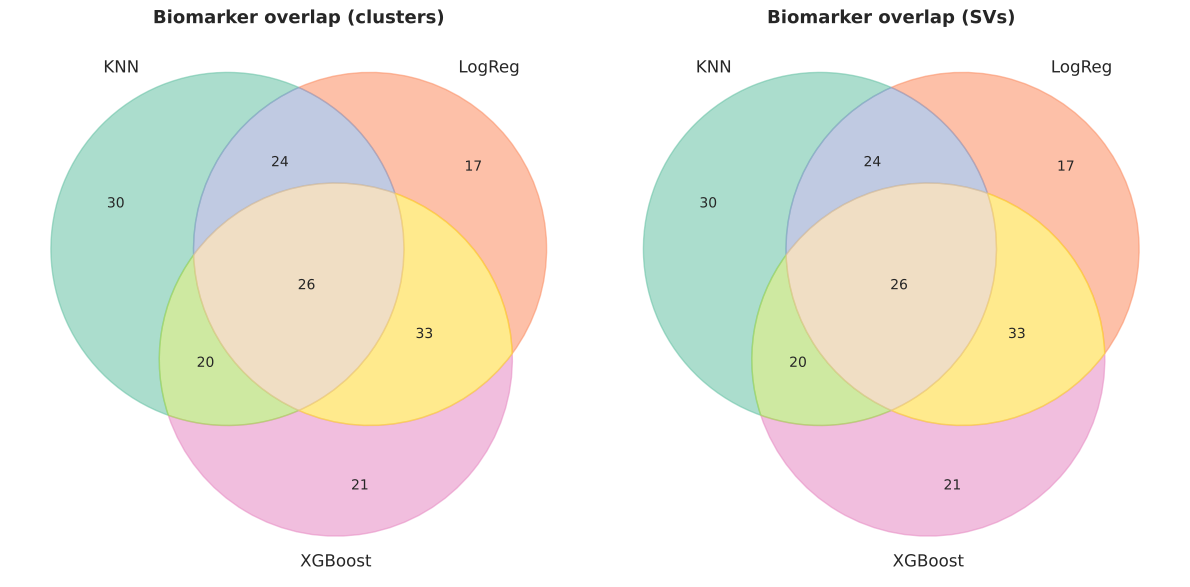

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

v1 = venn3(list(sets_cluster.values()), set_labels=list(sets_cluster.keys()), alpha=0.55, ax=axes[0])
axes[0].set_title("Biomarker overlap (clusters)", fontsize=13, weight='bold')

v2 = venn3(list(sets_features.values()), set_labels=list(sets_features.keys()), alpha=0.55, ax=axes[1])
axes[1].set_title("Biomarker overlap (SVs)", fontsize=13, weight='bold')

cmap = plt.get_cmap("Set2")
regions = ["100", "010", "110", "001", "101", "011", "111"]

for i, region in enumerate(regions):
    for v in (v1, v2):
        patch = v.get_patch_by_id(region)
        if patch:
            patch.set_color(cmap(i % cmap.N))

plt.tight_layout()
plt.savefig("Figures/11_biomarker_venn.png", dpi=300, bbox_inches='tight')
plt.show()

## **2. Which SVs are shared?**

In [4]:
K, L, X = sets_features['KNN'], sets_features['LogReg'], sets_features['XGBoost']
print(f'SVs shared by all three : {len(K & L & X)}')
print(f'KNN ∩ LogReg            : {len(K & L)}')
print(f'KNN ∩ XGBoost           : {len(K & X)}')
print(f'LogReg ∩ XGBoost        : {len(L & X)}')

SVs shared by all three : 26
KNN ∩ LogReg            : 50
KNN ∩ XGBoost           : 46
LogReg ∩ XGBoost        : 59


Let's list the SVs selected by at least two models, with their type, length and the score each model gave their cluster.

In [5]:
scores = (
    logreg[['feature', 'coefficient']]
    .merge(xgb[['feature', 'importance']].rename(columns={'importance': 'xgb_importance'}), on='feature', how='outer')
    .merge(knn[['feature', 'importance_mean']].rename(columns={'importance_mean': 'knn_importance'}), on='feature', how='outer')
)
scores['n_models'] = scores[['coefficient', 'xgb_importance', 'knn_importance']].notna().sum(axis=1)

shared = (scores[scores['n_models'] >= 2]
          .merge(all_selected[['feature', 'cluster', 'svtype', 'svlen']], on='feature')
          .sort_values(['n_models', 'xgb_importance'], ascending=False))

pd.set_option('display.max_rows', 100)
shared

,feature,coefficient,xgb_importance,knn_importance,n_models,cluster,svtype,svlen
89,sv__NZ_CP009157.1_403628_403709_DEL,-0.109388,0.035661,0.000000,3,29,DEL,81
54,sv__NZ_CP009157.1_1293887_3812462_INV,0.225886,0.034272,0.005556,3,161,INV,2518575
19,sv__NZ_CP009156.1_2447998_2448169_DUP,-0.162428,0.027554,0.000000,3,58,DUP,171
78,sv__NZ_CP009157.1_2934089_2934153_INV,-0.255066,0.026452,0.011111,3,75,INV,64
30,sv__NZ_CP009156.1_2957713_2957791_INV,0.183138,0.023742,0.004444,3,119,INV,78
...,...,...,...,...,...,...,...,...
87,sv__NZ_CP009157.1_3995158_3995256_DEL,-0.209608,NaN,0.000000,2,27,DEL,98
88,sv__NZ_CP009157.1_4016031_4016119_INV,-0.088673,NaN,0.000000,2,0,INV,88
93,sv__NZ_CP009157.1_493116_493182_DEL,0.160619,NaN,0.000000,2,64,DEL,66
95,sv__NZ_CP009157.1_729822_729873_INV,-0.183830,NaN,0.000000,2,2,INV,51


In [6]:
shared.to_csv("Results/biomarkers_shared.csv", index=False)
print(f"{len(shared)} SVs selected by at least two models saved to Results/biomarkers_shared.csv")

103 SVs selected by at least two models saved to Results/biomarkers_shared.csv


For logistic regression, a positive coefficient means that the presence of the SV is associated with **resistance**, a negative one with **susceptibility**.

## **3. What kind of SVs does each model pick?**
SV type composition and SV lengths of the biomarkers of each model, compared to all SVs that passed feature selection (background).

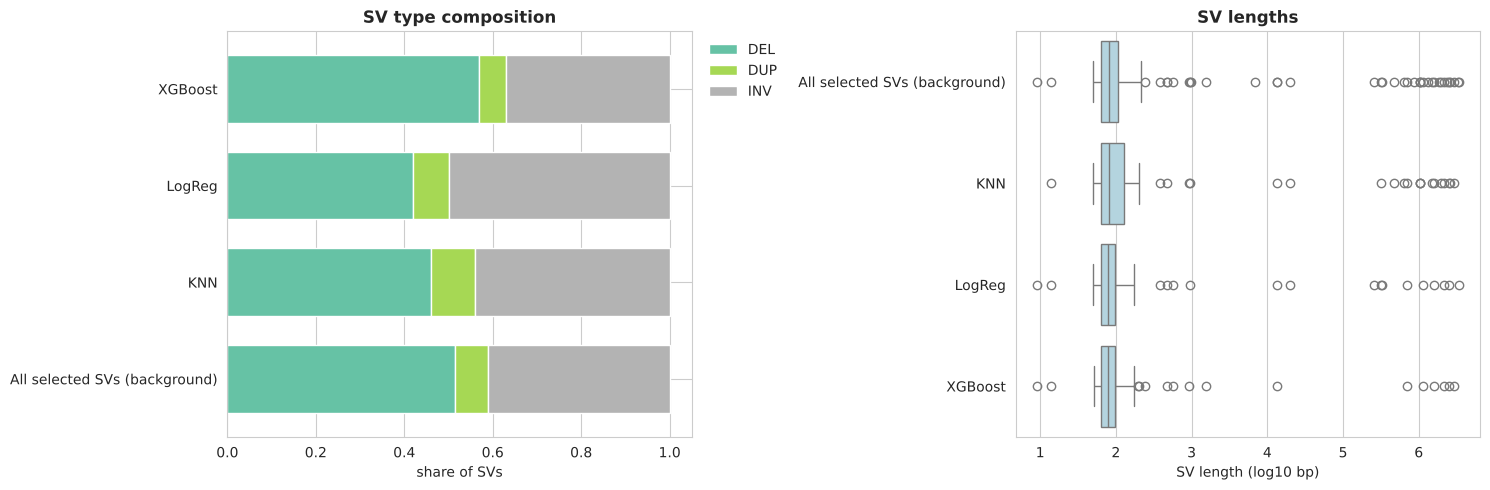

svtype,DEL,DUP,INV
model,,,
All selected SVs (background),51.5,7.5,41.0
KNN,46.0,10.0,44.0
LogReg,42.0,8.0,50.0
XGBoost,57.0,6.0,37.0


In [7]:
comp = pd.concat([
    all_selected.assign(model='All selected SVs (background)'),
    knn.assign(model='KNN'),
    logreg.assign(model='LogReg'),
    xgb.assign(model='XGBoost'),
], ignore_index=True)

order = ['All selected SVs (background)', 'KNN', 'LogReg', 'XGBoost']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

tab = pd.crosstab(comp['model'], comp['svtype'], normalize='index').loc[order]
tab.plot(kind='barh', stacked=True, ax=axes[0], colormap='Set2', width=0.7)
axes[0].set_xlabel('share of SVs')
axes[0].set_ylabel('')
axes[0].set_title('SV type composition', fontweight='bold')
axes[0].legend(bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)

sns.boxplot(data=comp, y='model', x=np.log10(comp['svlen'].clip(lower=1)), order=order, ax=axes[1], color='lightblue')
axes[1].set_xlabel('SV length (log10 bp)')
axes[1].set_ylabel('')
axes[1].set_title('SV lengths', fontweight='bold')

plt.tight_layout()
plt.savefig("Figures/11_biomarker_types.png", dpi=300, bbox_inches='tight')
plt.show()

(tab * 100).round(1)